# 07 – When Kaggle disagrees with the backtest: debugging submission v2

| Submission | Method | Backtest RMSLE | Kaggle |
|---|---|---|---|
| v1 | Level + weekday rule | 0.487 | 0.41457 |
| v2 | LightGBM (notebook 06) | 0.475 | **0.44253** |

The backtest said the model was better. Kaggle said it was clearly worse. Something was wrong, and the
tempting reactions are both bad:
- *"Kaggle is just noisy"*: maybe, but a gap of 0.03 in the wrong direction deserves an explanation first.
- *"Let's tune the model until Kaggle improves"*: that tunes on the test set, and hides the problem instead of finding it.

This notebook shows how the problem was found, without access to the test answers, and fixed.

**Plan:**
1. Where do v1 and v2 disagree?
2. What's special about those stores?
3. Which part of the data carried the problem? Two hypotheses, two experiments.
4. Why didn't the backtest catch it?
5. The fix, and its effect on the backtest and on Kaggle.

*Running time: about 12 minutes on a laptop: three experiment models in section 3 and the backtest in section 5.*

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_test, load_train
from src.dataset import build_table
from src.features import load_holidays, load_stores
from src.lags import closed_store_days
from src.metrics import rmsle
from src.model import backtest_model, fit, forecast, prepare
from src.validation import HORIZON, make_cutoffs

IMAGES = "../images"

train = load_train()
test = load_test()
wide = train.pivot_table(index="date", columns=["store_nbr", "family"], values="sales", observed=True)

## 1. Where do v1 and v2 disagree?

We don't know the test answers, but we do know both forecasts. If v2 is worse than v1, the problem must be
somewhere **where they differ**. So we measure their difference on the metric's scale (log1p) and ask which
stores and families it comes from.

In [2]:
v1 = pd.read_csv("../submissions/v1_level_weekday.csv")
v2 = pd.read_csv("../submissions/v2_lightgbm.csv")
both = test.merge(v1, on="id").merge(v2, on="id", suffixes=("_v1", "_v2"))
both["squared_log_diff"] = (np.log1p(both["sales_v2"]) - np.log1p(both["sales_v1"])) ** 2

def share_by(column):
    total = both.groupby(column, observed=True)["squared_log_diff"].sum()
    return (total / total.sum()).sort_values(ascending=False).head(5).round(3)

print("Share of the v1-v2 difference, by store:")
print(share_by("store_nbr").to_string())
print("\nBy family:")
print(share_by("family").to_string())

Share of the v1-v2 difference, by store:
store_nbr
25    0.279
18    0.225
10    0.020
42    0.016
43    0.016

By family:
family
SCHOOL AND OFFICE SUPPLIES    0.095
BREAD/BAKERY                  0.050
LIQUOR,WINE,BEER              0.050
GROCERY I                     0.047
DAIRY                         0.044


**Two stores out of 54, 18 and 25, cause half of the difference.** No family stands out like that.
A problem concentrated in a few stores usually means something happened *to those stores*, not a general weakness of the model.

## 2. What's special about stores 18 and 25?

First, compare the forecasts with what these stores have been selling recently.

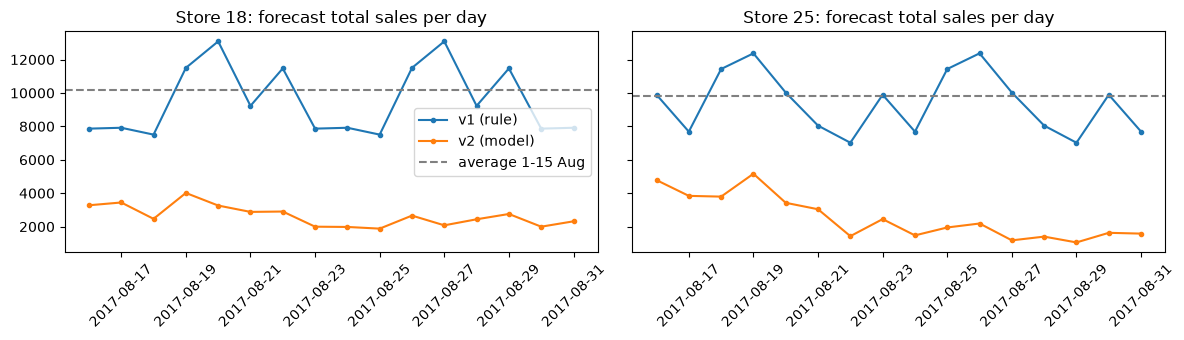

In [3]:
store_daily = train.groupby(["date", "store_nbr"], observed=True)["sales"].sum().unstack()
recent = store_daily.loc["2017-08-01":"2017-08-15", [18, 25]].mean()

forecasts = both[both["store_nbr"].isin([18, 25])].groupby(["store_nbr", "date"], observed=True)[["sales_v1", "sales_v2"]].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, store in zip(axes, [18, 25]):
    part = forecasts.loc[store]
    ax.plot(part.index, part["sales_v1"], marker="o", markersize=3, label="v1 (rule)")
    ax.plot(part.index, part["sales_v2"], marker="o", markersize=3, label="v2 (model)")
    ax.axhline(recent[store], color="grey", linestyle="--", label="average 1-15 Aug")
    ax.set_title(f"Store {store}: forecast total sales per day")
    ax.tick_params(axis="x", rotation=45)
axes[0].legend()
fig.tight_layout()
fig.savefig(f"{IMAGES}/v2_stores_18_25.png", dpi=120)
plt.show()

v1 forecasts both stores around their recent level. **v2 forecasts store 18 at a fraction of it for the whole period,
and store 25 drops suddenly on 22 August.** A sudden drop on a specific date is a strong clue: something in the
features changes on that date.

Notebook 03 already met these two stores. Let's look at their history:

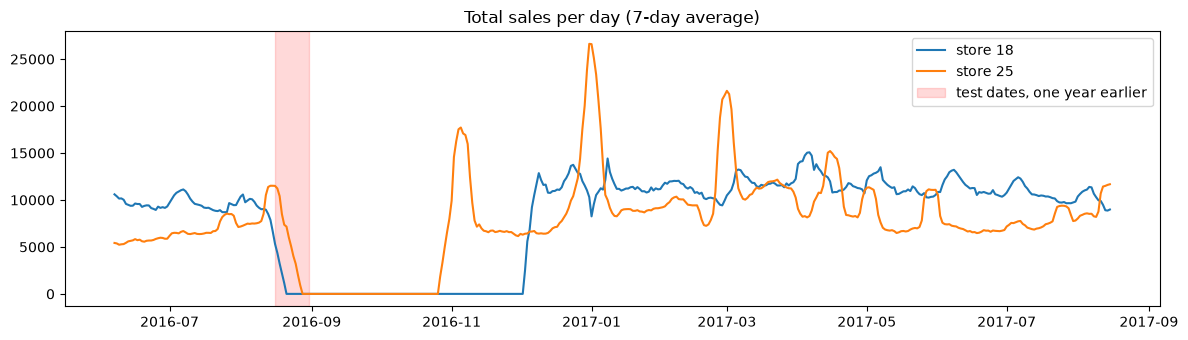

Store 18 closed from 2016-08-15 to 2016-12-02 (110 days)
Store 25 closed from 2016-08-22 to 2016-10-26 (66 days)


In [4]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for store in [18, 25]:
    ax.plot(store_daily.loc["2016-06-01":, store].rolling(7).mean(), label=f"store {store}")
ax.axvspan(pd.Timestamp("2016-08-16"), pd.Timestamp("2016-08-31"), color="red", alpha=0.15, label="test dates, one year earlier")
ax.set_title("Total sales per day (7-day average)")
ax.legend()
fig.tight_layout()
fig.savefig(f"{IMAGES}/stores_18_25_history.png", dpi=120)
plt.show()

for store in [18, 25]:
    closed = store_daily.index[store_daily[store] == 0]
    closed_2016 = closed[(closed >= "2016-06-01") & (closed <= "2016-12-31")]
    print(f"Store {store} closed from {closed_2016.min():%Y-%m-%d} to {closed_2016.max():%Y-%m-%d} ({len(closed_2016)} days)")

Both stores were **closed** for weeks in 2016, and the closures cover the test dates **one year earlier**
(store 25's closure starts on 22 August 2016, the exact date its v2 forecast drops in 2017).

## 3. Which part of the data carried the problem?

We have a suspect event (the closures one year earlier) but not yet the mechanism. Before the fix, a closed day
was stored as **sales = 0**, and that zero could reach the model in two ways:

1. **as a feature:** `lag_364` looks exactly 52 weeks back, so for the test period it saw the closed days;
2. **as a training target:** the closed days of 2016 were ordinary training rows saying "this store, on these dates, sold 0".

### Hypothesis 1: `lag_364`

It fits the dates well. For store 25, count how many of its 33 families had `lag_364` = 0 under the old rule:

In [5]:
test_dates = pd.date_range("2017-08-16", "2017-08-31", name="date")
store_25 = wide.xs(25, axis=1, level="store_nbr")           # dates x families
year_before = store_25.reindex(test_dates - pd.Timedelta(days=364))
old_lag_364_is_zero = (year_before == 0).mean(axis=1)
old_lag_364_is_zero.index = test_dates
old_lag_364_is_zero.round(2).rename("share of families with lag_364 = 0").to_frame().T

date,2017-08-16,2017-08-17,2017-08-18,2017-08-19,2017-08-20,2017-08-21,2017-08-22,2017-08-23,2017-08-24,2017-08-25,2017-08-26,2017-08-27,2017-08-28,2017-08-29,2017-08-30,2017-08-31
share of families with lag_364 = 0,0.27,0.21,0.24,0.21,0.24,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


From 21 August on, `lag_364` is 0 for every family of store 25. That's close to the date its forecast drops,
but look carefully: the big drop is on **22 August** (about 3,000 → 1,400), the calendar date the store closed in 2016,
one day *after* `lag_364` changes. A first hint that something else is going on. And in any case, two dates lining up
isn't proof. **Test it:** rebuild the old model, then forecast
the test period twice, once normally and once with `lag_364` hidden (NaN) for stores 18 and 25.
If `lag_364` is the cause, hiding it should bring the forecasts back up.

`build_table` has two switches to rebuild the data as it was before the fix (both `False` = the old behaviour).
Each model below takes a few minutes to train.

In [6]:
stores, holidays = load_stores(), load_holidays()
test_index = pd.DatetimeIndex(test_dates, name="date")

def store_forecasts(data, model):
    # Average forecast per day, for stores 18 and 25.
    f = forecast(model, data, test_index)
    return {store: f[store].sum(axis=1).mean() for store in [18, 25]}

old_data = prepare(build_table(train, stores, holidays, end="2017-08-31",
                               mask_closed_features=False, drop_closed_targets=False))
old_model, _ = fit(old_data, "2017-08-15")

hidden = old_data.copy()
in_test_18_25 = hidden["date"].isin(test_index) & hidden["store_nbr"].isin([18, 25])
hidden.loc[in_test_18_25, "lag_364"] = np.nan

experiments = {"recent level (1-15 Aug)": recent.to_dict(),
               "old model (= v2)": store_forecasts(old_data, old_model),
               "old model, lag_364 hidden": store_forecasts(hidden, old_model)}
pd.DataFrame(experiments).T.round(0)

,18,25
recent level (1-15 Aug),10185.0,9831.0
old model (= v2),2648.0,2525.0
"old model, lag_364 hidden",2055.0,3603.0


**Hypothesis 1 rejected.** With `lag_364` hidden, both stores are still forecast far below their recent level.
`lag_364` may contribute a little, but it isn't the main cause. Good thing we tested it: the README and the first
version of the fix's comments blamed `lag_364`, a plausible story that turned out to be wrong.

### Hypothesis 2: the training targets

Two more models, each fixing only one of the two paths:

In [7]:
targets_fixed = prepare(build_table(train, stores, holidays, end="2017-08-31",
                                    mask_closed_features=False, drop_closed_targets=True))
features_fixed = prepare(build_table(train, stores, holidays, end="2017-08-31",
                                     mask_closed_features=True, drop_closed_targets=False))
experiments["only the targets fixed"] = store_forecasts(targets_fixed, fit(targets_fixed, "2017-08-15")[0])
experiments["only the features fixed"] = store_forecasts(features_fixed, fit(features_fixed, "2017-08-15")[0])
pd.DataFrame(experiments).T.round(0)

,18,25
recent level (1-15 Aug),10185.0,9831.0
old model (= v2),2648.0,2525.0
"old model, lag_364 hidden",2055.0,3603.0
only the targets fixed,9336.0,7834.0
only the features fixed,2427.0,2449.0


**Hypothesis 2 confirmed.** Removing the closed days as **training targets** alone brings both stores back to
their normal level; fixing only the features doesn't.

**What the model had learned:** in 2016, store 25 had dozens of training rows saying "August, from the 22nd on:
sales 0", and store 18 "from 15 August: sales 0". With `store_nbr`, `month` and `day_of_month` as features, a tree
model can memorise exactly that, and in 2017 it repeated it. The model did what it was trained to do; the training
data told it something false: that these stores have no demand at those dates.

**The underlying mistake:** two different facts, *"the store was closed"* and *"nobody bought anything"*, were stored
as the same number. We avoided exactly this for Christmas in notebook 05 (missing days became NaN, "unknown"),
but didn't apply the idea to store closures.

## 4. Why didn't the backtest catch it?

The model memorised "closed on these calendar dates". So it only goes wrong on dates when a store was closed
**at the same time one year earlier**. How many (date, series) pairs in each window fall on such a date?

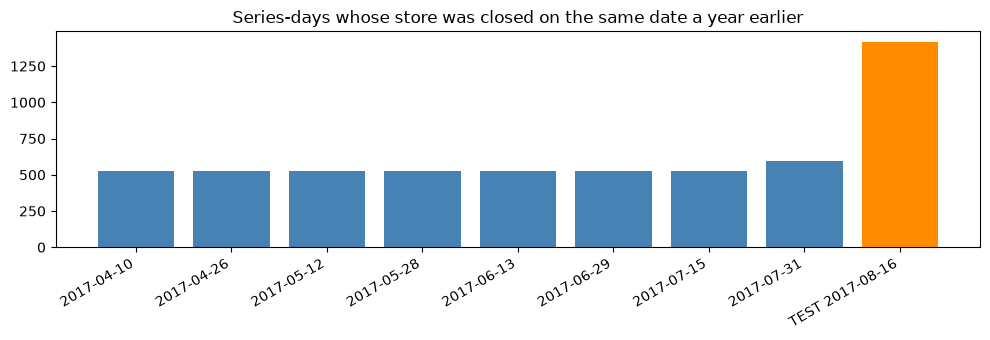

2017-04-10          528
2017-04-26          528
2017-05-12          528
2017-05-28          528
2017-06-13          528
2017-06-29          528
2017-07-15          528
2017-07-31          594
TEST 2017-08-16    1419
Name: series-days whose store was closed a year earlier, dtype: int64

In [8]:
closed = closed_store_days(wide)

def closed_a_year_before(dates):
    # How many (date, series) pairs fall on a date when that store was closed 52 weeks earlier?
    back = pd.DatetimeIndex(dates) - pd.Timedelta(days=364)
    return int(closed.reindex(back).fillna(False).to_numpy().sum())

cutoffs = make_cutoffs(wide.index.max(), n_windows=8)
counts = {
    (c + pd.Timedelta(days=1)).strftime("%Y-%m-%d"): closed_a_year_before(pd.date_range(c + pd.Timedelta(days=1), periods=HORIZON))
    for c in cutoffs
}
counts["TEST 2017-08-16"] = closed_a_year_before(test_dates)
counts = pd.Series(counts, name="series-days whose store was closed a year earlier")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(counts.index, counts.values, color=["steelblue"] * 8 + ["darkorange"])
ax.set_title("Series-days whose store was closed on the same date a year earlier")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(f"{IMAGES}/closed_lookups.png", dpi=120)
plt.show()
counts

Seven backtest windows have exactly 528 = 16 days × 33 families: that's store 52, which hadn't opened yet a year
earlier. The newest window has 66 more: its last two days touch the start of store 18's closure. (Store 52 was a problem too, but a different one: before the fix its 1,566 pre-opening days were training rows
saying "store 52 sells nothing", whatever the date.) The test period has nearly three times as many, because the
closures of stores 18 and 25 started in mid-August 2016. **The backtest windows (April to mid-August) never reached
those dates.**

**Lesson:** a backtest is a sample of situations. It protects you against problems that show up in its windows,
not against everything. When the test period has something special (here: what happened a year before it),
check that your backtest contains it, or look for it directly. Notebook 03 did find these closures, but only asked
how they affected *that* window, not what a model would learn from them.

## 5. The fix

`closed_store_days` in `src/lags.py`: if a store's total sales on a day are 0, across all 33 families, the store
was closed. For that store and day:
- **features:** the sales become NaN (unknown), so lags and averages skip them, exactly like Christmas;
- **target:** also NaN, so the model doesn't train on them (a closure can't be predicted from sales history).

Section 3 showed that the targets are what mattered for stores 18 and 25. Masking the features too keeps
averages from mixing "closed" with "no demand", the same reasoning as for Christmas.

A zero in one family while the store was open stays a real zero: that **is** information about demand.
`tests/test_lags.py::test_closed_store_day_is_unknown_not_zero` checks both cases.
(Writing that test also caught a mistake in the test itself: the fake data had stores with a single family,
where "one family at zero" *is* "the whole store at zero".)

How many days does the rule mark?

In [9]:
store_level = closed.T.groupby(level="store_nbr", observed=True).first().T   # dates x stores
print(f"Closed store-days: {int(store_level.to_numpy().sum()):,} "
      f"({store_level.to_numpy().mean():.1%} of all store-days)")
print("Stores with the most closed days:")
print(store_level.sum().sort_values(ascending=False).head(6).astype(int).to_string())

Closed store-days: 7,330 (8.1% of all store-days)
Stores with the most closed days:
store_nbr
52    1566
22    1011
42     962
21     934
29     808
20     773


Besides New Year's Day and the 2016 closures, most closed days are **before a store opened**: stores 20, 21, 22,
29, 42, 52 and 53 opened during the period covered by the data. Before the fix, their pre-opening months were
training rows saying "this store sells nothing". That's why the fix also matters for store 52 (notebook 06).

### The effect on the backtest

Same 8 windows, same model settings, only the data preparation changed (about 35 minutes).
The v2 numbers come from notebook 06.

In [10]:
data = prepare(build_table(train, load_stores(), load_holidays(), end="2017-08-31"))
fixed_scores, _ = backtest_model(data, wide, cutoffs)

v2_scores = pd.Series([0.6083, 0.6956, 0.4326, 0.4026, 0.3946, 0.3836, 0.4076, 0.4715],
                      index=fixed_scores.index)  # notebook 06, before the fix
comparison = pd.DataFrame({"v2 (closed = 0)": v2_scores, "fixed (closed = unknown)": fixed_scores["RMSLE"],
                           "trees": fixed_scores["trees"]})
comparison.loc["mean"] = comparison.mean()
comparison.round(4)

,v2 (closed = 0),fixed (closed = unknown),trees
window starts,,,
2017-04-10,0.6083,0.6162,1585.0
2017-04-26,0.6956,0.4507,117.0
2017-05-12,0.4326,0.4274,1947.0
2017-05-28,0.4026,0.4000,2004.0
2017-06-13,0.3946,0.3931,1504.0
2017-06-29,0.3836,0.3835,1194.0
2017-07-15,0.4076,0.4059,642.0
2017-07-31,0.4715,0.4672,363.0
mean,0.4746,0.4430,1169.5


**The mean improves from 0.475 to about 0.443.** Most of it is the late-April window (about 0.70 → 0.45):
store 52's months before opening no longer teach the model "store 52 sells nothing", so it doesn't forecast zero for
a store that has just opened. The other windows improve a little or stay the same; the first one gets slightly worse
(store 52 opens *inside* it, on day 11, which no feature can know).

The fixed model also beats the best rule (0.487) by a much larger margin than v2 did.

### Submission v3

In [11]:
final_model, final_trees = fit(data, "2017-08-15")
predicted = forecast(final_model, data, pd.DatetimeIndex(test_dates, name="date"))
long = predicted.unstack().rename("sales").reset_index()
v3 = test.merge(long, on=["store_nbr", "family", "date"], how="left")[["id", "sales"]]
assert len(v3) == len(test) and v3["sales"].notna().all() and (v3["sales"] >= 0).all()
v3.to_csv("../submissions/v3_lightgbm_closed_stores.csv", index=False)

check = test.merge(v3, on="id")
print(f"Trees: {final_trees}")
print("Store 18 and 25, forecast average per day:",
      check[check["store_nbr"].isin([18, 25])].groupby("store_nbr", observed=True)["sales"].sum().div(16).round(0).to_dict())
print("Their average 1-15 August:", recent.round(0).to_dict())

Trees: 1406
Store 18 and 25, forecast average per day: {18: 9441.0, 25: 8066.0}
Their average 1-15 August: {18: 10185.0, 25: 9831.0}


Stores 18 and 25 are now forecast close to their recent level.

| Submission | Method | Backtest RMSLE | Kaggle |
|---|---|---|---|
| v1 | Level + weekday rule | 0.487 | 0.41457 |
| v2 | LightGBM | 0.475 | 0.44253 |
| **v3** | **LightGBM, closed store days = unknown** | **0.443** | **0.40358** |

v3 is the best score so far, and the backtest and Kaggle now agree on the ranking.

## A checklist for next time

When the test score disagrees with the validation score:

1. **Don't tune yet.** First find out *why*.
2. **Compare with a submission you trust.** Where the two disagree is where the problem must be.
3. **Look for concentration.** Two stores out of 54 causing half the difference points to an event, not a weak model.
4. **Look for dates.** A forecast that changes on one specific date means a feature changes on that date.
5. **Turn each explanation into an experiment.** "It's `lag_364`" fitted the dates perfectly and was still wrong.
6. **Ask what each value means.** "Closed" and "zero demand" are different facts; storing both as 0 mixes them up.
7. **Ask why validation missed it,** and whether the test period has something your validation windows don't.
8. **Fix the cause, add a test** so the mistake can't come back, and re-run the validation.